In [5]:
import pandas as pd
import polars as pl
import svy
import numpy as np
import matplotlib.pyplot as plt

In [3]:
h3_df = pd.read_csv('../data/processed/h3_analytic_sample.csv')
h3_pooled = h3_df.assign(wtmec2yr_pooled = h3_df['WTMEC2YR'] / 2)

design = svy.Design(
    stratum='SDMVSTRA',
    psu='SDMVPSU',
    wgt='wtmec2yr_pooled'
)
h3_pl = pl.from_pandas(h3_pooled)
sample = svy.Sample(h3_pl, design=design)

model_h3 = svy.GLM(sample)
model_h3.fit(
    y='LBXCRP',
    x=['LBXT3F', 'RIDAGEYR', svy.Cat('RIAGENDR', ref=1), 'BMXBMI'],
    family='gaussian',
)
print(model_h3)

GLM: Gaussian (identity)
  Modeling : LBXCRP
  n            : 6271          DF Residuals : 28
  Deviance     : 3165.4488     Scale        : 100.2295
  AIC          : 13524.8187    BIC          : -
  R-squared    : 0.07970       R-sq (adj)   : 0.07912
  F-stat (adj) : 46.26766      Prob (F-adj) : <0.001

Coefficients:
  Term          Coef.     Std.Err.  t         P>|t|   [0.025    0.975]  
  ------------  --------  --------  --------  ------  --------  --------
  _intercept_   -0.57569  0.08591   -6.70125  <0.001  -0.75166  -0.39972
  LBXT3F        -0.01326  0.01779   -0.74550  0.4622  -0.04969  0.02317 
  RIDAGEYR      0.00148   0.00062   2.38853   0.0239  0.00021   0.00275 
  RIAGENDR_2.0  0.12149   0.02154   5.64080   <0.001  0.07737   0.16561 
  BMXBMI        0.03049   0.00281   10.86629  <0.001  0.02474   0.03623 


/var/folders/rs/yth10b8d4v1043_hxt3sv4x40000gn/T/ipykernel_17317/461654983.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  h3_pooled = h3_df.assign(wtmec2yr_pooled = h3_df['WTMEC2YR'] / 2)


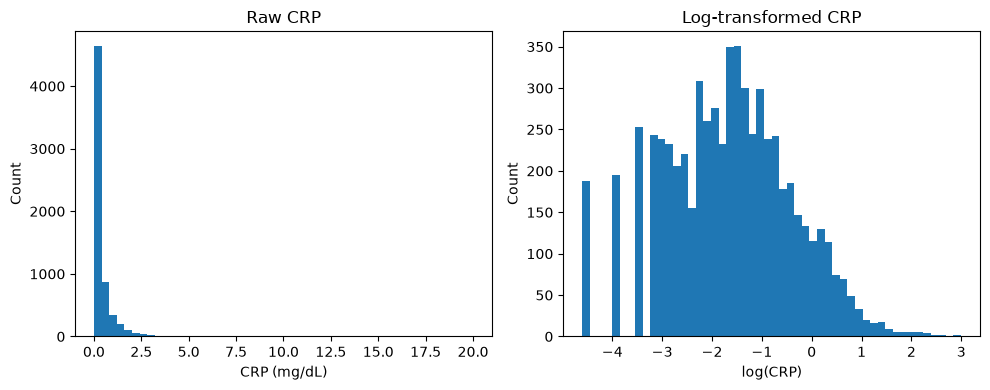

In [8]:
h3_pooled['log_crp'] = np.log(h3_pooled['LBXCRP'])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(h3_pooled['LBXCRP'], bins=50)
axes[0].set_title('Raw CRP')
axes[0].set_xlabel('CRP (mg/dL)')
axes[0].set_ylabel('Count')

axes[1].hist(h3_pooled['log_crp'], bins=50)
axes[1].set_title('Log-transformed CRP')
axes[1].set_xlabel('log(CRP)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

/var/folders/rs/yth10b8d4v1043_hxt3sv4x40000gn/T/ipykernel_17317/1602903247.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  h3_pooled['log_crp'] = np.log(h3_pooled['LBXCRP'])
